# PR20: preparación exploratoria de producción horaria

Se explora la producción de 2020. Los timestamps se interpretan como UTC; cada fila horaria representa el intervalo `[t, t + 1 h)`. Se calcula la potencia media en W y se estima la energía de una hora en kWh como potencia media / 1000. Esta estimación supone que las lecturas disponibles representan la hora completa.

Se exige una cobertura mínima del 99 % (3.564 de las 3.600 lecturas esperadas). Las horas con cobertura insuficiente mantienen energía ausente. Los retardos de 1, 2 y 24 horas se calculan sobre la rejilla horaria completa antes de eliminar filas incompletas. La predicción se emite al comienzo de la hora objetivo usando únicamente horas terminadas.

**Estado y límites:** todavía no hay entrenamiento ni evaluación con separación cronológica. Esta exploración horaria difiere del objetivo de potencia media en 15 minutos descrito en `docs/data_contract.md`; queda pendiente acordar resolución y objetivo con la parte de irradiación antes de integrar. El notebook carga el CSV anual completo y requiere varios GB de memoria. Las salidas existentes proceden de ejecuciones previas; esta preparación para GitHub comprueba estructura y sintaxis sin repetir la carga completa.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

print("Python del notebook:", Path.cwd())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python del notebook: c:\Users\alvar\Desktop\ICAI-MÁSTER\Aprendizaje_Automático\ffva\fvaa\notebooks
pandas: 3.0.6
NumPy: 2.5.3
scikit-learn: 1.9.1


In [3]:
from pathlib import Path

ROOT_DIR = Path.cwd()

# Si el notebook se ejecuta desde la carpeta notebooks, subimos a la raíz del proyecto
if ROOT_DIR.name.lower() == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

RAW_DIR = ROOT_DIR / "data" / "raw"

print("Raíz del proyecto:", ROOT_DIR)
print("Carpeta de datos:", RAW_DIR)
print("¿Existe?:", RAW_DIR.exists())

if RAW_DIR.exists():
    for archivo in RAW_DIR.rglob("*"):
        if archivo.is_file():
            tamaño_mb = archivo.stat().st_size / (1024 ** 2)
            print(f"{archivo.name} — {tamaño_mb:.2f} MB")

Raíz del proyecto: c:\Users\alvar\Desktop\ICAI-MÁSTER\Aprendizaje_Automático\ffva\fvaa
Carpeta de datos: c:\Users\alvar\Desktop\ICAI-MÁSTER\Aprendizaje_Automático\ffva\fvaa\data\raw
¿Existe?: True
metadata.csv — 0.00 MB
pr20_rad_2019.csv — 3.70 MB
pr20_rad_2020.csv — 35.34 MB
pr20_rad_2021.csv — 35.24 MB
pr20_rad_2022.csv — 35.20 MB
pr20_rad_2023.csv — 35.23 MB
pr20_prod_2019.csv — 190.52 MB
pr20_prod_2020.csv — 1746.00 MB
pr20_prod_2021.csv — 1739.40 MB
pr20_prod_2022.csv — 1738.23 MB
pr20_prod_2023.csv — 1711.52 MB


In [9]:
path_prueba = RAW_DIR /"PTProsumer"/ "PR20"/ "pr20_prod_2020.csv"/"pr20_prod_2020.csv"

df_muestra = pd. read_csv(path_prueba)

df_muestra.head()

,timestamp,voltage_P1,current_P1,active_power_P1,apparent_power_P1,reactive_power_P1,power_factor_P1,frequency
0,2020-01-01 00:00:00,233.6,0.247,0.0,57.9,57.9,0.018,50.1
1,2020-01-01 00:00:01,233.6,0.247,0.0,57.8,57.8,0.017,50.1
2,2020-01-01 00:00:02,233.6,0.247,0.0,57.9,57.9,0.017,50.1
3,2020-01-01 00:00:03,233.6,0.247,0.0,57.9,57.9,0.017,50.1
4,2020-01-01 00:00:04,233.6,0.247,0.0,57.8,57.8,0.017,50.1


In [10]:
df_muestra.columns.tolist()

['timestamp',
 'voltage_P1',
 'current_P1',
 'active_power_P1',
 'apparent_power_P1',
 'reactive_power_P1',
 'power_factor_P1',
 'frequency']

In [11]:
df_muestra.info()

<class 'pandas.DataFrame'>
RangeIndex: 31581875 entries, 0 to 31581874
Data columns (total 8 columns):
 #   Column             Dtype  
---  ------             -----  
 0   timestamp          str    
 1   voltage_P1         float64
 2   current_P1         float64
 3   active_power_P1    float64
 4   apparent_power_P1  float64
 5   reactive_power_P1  float64
 6   power_factor_P1    float64
 7   frequency          float64
dtypes: float64(7), str(1)
memory usage: 1.9 GB


In [12]:
df_muestra["timestamp"] = pd.to_datetime(df_muestra["timestamp"])

In [13]:
df_prod = df_muestra

In [14]:
df_prod["hora"] = df_prod["timestamp"].dt.hour
df_prod["mes"] = df_prod["timestamp"].dt.month

In [18]:
print(df_prod["hora"].head())

0    0
1    0
2    0
3    0
4    0
Name: hora, dtype: int32


In [19]:
print(df_prod["mes"].head())

0    1
1    1
2    1
3    1
4    1
Name: mes, dtype: int32


In [20]:
fechas = df_prod["timestamp"]

print("Primera fecha:", fechas.min())
print("Última fecha:", fechas.max())
print("Fechas ausentes:", fechas.isna().sum())
print("¿Están ordenadas?:", fechas.is_monotonic_increasing)
print("Fechas duplicadas:", fechas.duplicated().sum())

Primera fecha: 2020-01-01 00:00:00
Última fecha: 2020-12-31 23:59:59
Fechas ausentes: 0
¿Están ordenadas?: True
Fechas duplicadas: 0


In [21]:
intervalos = fechas.diff()

print("Intervalos más frecuentes:")
print(intervalos.value_counts().head(10))

Intervalos más frecuentes:
timestamp
0 days 00:00:01    31549755
0 days 00:00:02       31864
0 days 00:00:03          42
0 days 00:00:04          26
0 days 00:00:05          22
0 days 00:00:06          20
0 days 00:00:07          18
0 days 00:00:11          10
0 days 00:00:08           9
0 days 00:00:12           8
Name: count, dtype: int64


In [ ]:
#Para conocer la cobertura anual 
esperadas = int(
    (fechas.max() - fechas.min()).total_seconds()
) + 1

faltantes = esperadas - len(fechas)

print("Registros esperados:", esperadas)
print("Registros disponibles:", len(fechas))
print("Segundos sin registro:", faltantes)
print(f"Cobertura temporal: {100 * len(fechas) / esperadas:.3f}%")
print("Mayor intervalo entre registros:", intervalos.max())

Registros esperados: 31622400
Registros disponibles: 31581875
Segundos sin registro: 40525
Cobertura temporal: 99.872%
Mayor intervalo entre registros: 0 days 00:24:43


In [23]:
potencia = df_prod["active_power_P1"]

print(potencia.describe())
print("Valores ausentes:", potencia.isna().sum())
print("Valores negativos:", (potencia < 0).sum())

count    3.158188e+07
mean     1.300923e+02
std      1.956327e+02
min      0.000000e+00
25%      0.000000e+00
50%      9.000000e-01
75%      2.149000e+02
max      7.442000e+02
Name: active_power_P1, dtype: float64
Valores ausentes: 0
Valores negativos: 0


In [24]:
cobertura_horaria = (
    df_prod.resample("1h", on="timestamp")["active_power_P1"]
    .count()
    .rename("registros")
    .to_frame()
)

# Esperamos 3.600 medidas por hora, una por segundo
cobertura_horaria["cobertura_pct"] = (
    cobertura_horaria["registros"] / 3600 * 100
)

display(cobertura_horaria["cobertura_pct"].describe())

# Las diez horas con menor cobertura
display(cobertura_horaria.nsmallest(10, "cobertura_pct"))

count    8784.000000
mean       99.871847
std         0.701383
min        58.083333
25%        99.888889
50%        99.888889
75%        99.916667
max        99.916667
Name: cobertura_pct, dtype: float64

,registros,cobertura_pct
timestamp,,
2020-03-21 01:00:00,2091,58.083333
2020-04-16 00:00:00,2879,79.972222
2020-01-02 01:00:00,2935,81.527778
2020-07-06 00:00:00,3005,83.472222
2020-09-25 00:00:00,3039,84.416667
2020-08-29 00:00:00,3083,85.638889
2020-01-27 01:00:00,3118,86.611111
2020-08-02 00:00:00,3124,86.777778
2020-12-13 01:00:00,3128,86.888889


In [25]:
cobertura_horaria["hora_valida"] = (
    cobertura_horaria["cobertura_pct"] >= 99
)

print("Horas totales:", len(cobertura_horaria))
print("Horas válidas:", cobertura_horaria["hora_valida"].sum())
print("Horas por debajo del 99 %:",
      (~cobertura_horaria["hora_valida"]).sum())

Horas totales: 8784
Horas válidas: 8762
Horas por debajo del 99 %: 22


In [26]:
rutas_metadata = [
    ruta
    for ruta in RAW_DIR.rglob("metadata.csv")
    if ruta.is_file()
]

for ruta in rutas_metadata:
    print(ruta)

c:\Users\alvar\Desktop\ICAI-MÁSTER\Aprendizaje_Automático\ffva\fvaa\data\raw\PTProsumer\metadata.csv


In [27]:
metadata = pd.read_csv(rutas_metadata[0])
display(metadata)

,ID,Type,Phases_Cons,Phases_Prod,Peak_Power_Cons,Peak_Power_Prod,Collection_Start,Collection _End,Complete_Net-Load,Complete_Production
0,PR_01,Office,1,1,10.35,1.50,29/03/2018,21/02/2022,85.13,85.13
1,PR_02,House,3,1,10.35,2.70,01/05/2018,21/02/2022,94.94,95.04
2,PR_03,Restaurant,3,3,20.70,3.92,25/05/2018,20/05/2022,96.75,97.46
3,PR_04,House,1,1,6.90,1.25,29/05/2018,24/01/2020,99.20,99.28
4,PR_05,Apartment,1,1,6.90,0.50,06/06/2018,13/03/2023,95.53,95.55
5,PR_06,House,1,1,3.45,0.75,09/06/2018,21/02/2022,98.63,99.61
6,PR_07,House,1,1,6.90,0.39,19/06/2018,27/03/2021,99.40,99.40
7,PR_08,House,1,1,6.90,1.50,20/06/2018,20/09/2018,98.20,98.20
8,PR_09,House,1,1,6.90,1.50,23/06/2018,31/12/2023,87.69,87.68
9,PR_10,House,1,1,10.35,0.50,28/06/2018,24/06/2020,97.88,97.88


In [28]:
df_prod["timestamp"] = pd.to_datetime(df_prod["timestamp"], utc=True)

In [29]:
df_horario = (
    df_prod.resample("1h", on="timestamp", closed="left", label="left")
    ["active_power_P1"]
    .agg(potencia_media_w="mean", registros="count")
)

df_horario["cobertura_pct"] = df_horario["registros"] / 3600 * 100
df_horario["hora_valida"] = df_horario["cobertura_pct"] >= 99

In [30]:
df_horario["energia_estimada_kwh"] = (
    df_horario["potencia_media_w"] / 1000
).where(df_horario["hora_valida"])

display(df_horario.head())

,potencia_media_w,registros,cobertura_pct,hora_valida,energia_estimada_kwh
timestamp,,,,,
2020-01-01 00:00:00+00:00,0.0,3596,99.888889,True,0.0
2020-01-01 01:00:00+00:00,0.0,3596,99.888889,True,0.0
2020-01-01 02:00:00+00:00,0.0,3596,99.888889,True,0.0
2020-01-01 03:00:00+00:00,0.0,3597,99.916667,True,0.0
2020-01-01 04:00:00+00:00,0.0,3596,99.888889,True,0.0


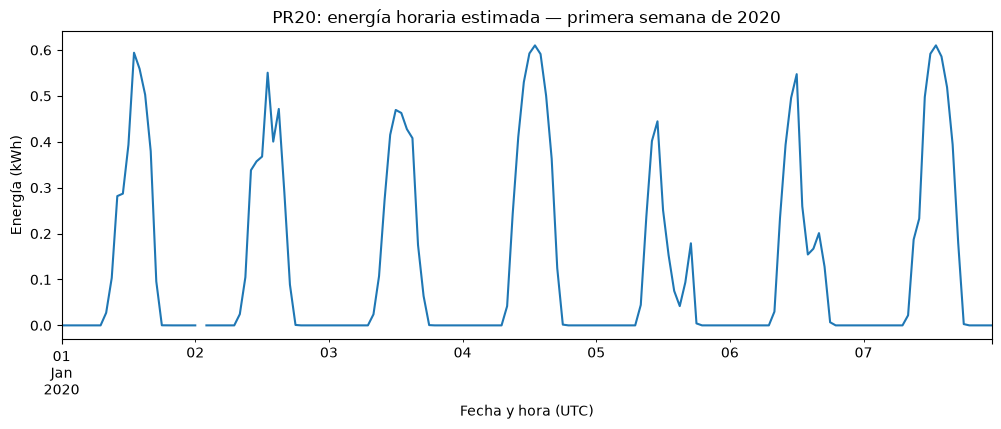

In [31]:
df_horario.loc[
    "2020-01-01":"2020-01-07", "energia_estimada_kwh"
].plot(
    figsize=(12, 4),
    title="PR20: energía horaria estimada — primera semana de 2020",
    xlabel="Fecha y hora (UTC)",
    ylabel="Energía (kWh)"
)

plt.show()

In [32]:
print(df_horario["energia_estimada_kwh"].describe())
print(
    "Horas sin energía estimada:",
    df_horario["energia_estimada_kwh"].isna().sum()
)

count    8762.000000
mean        0.130383
std         0.187520
min         0.000000
25%         0.000000
50%         0.003469
75%         0.244001
max         0.645599
Name: energia_estimada_kwh, dtype: float64
Horas sin energía estimada: 22


In [33]:
df_modelo = pd.DataFrame(index=df_horario.index)

energia = df_horario["energia_estimada_kwh"]

# Objetivo: energía de la hora que comienza en el instante de predicción
df_modelo["objetivo_kwh"] = energia

# Entradas: energía de horas que ya han terminado
df_modelo["energia_anterior_1h"] = energia.shift(1)
df_modelo["energia_anterior_2h"] = energia.shift(2)
df_modelo["energia_anterior_24h"] = energia.shift(24)

display(df_modelo.loc["2020-01-02 09:00":"2020-01-02 12:00"])

,objetivo_kwh,energia_anterior_1h,energia_anterior_2h,energia_anterior_24h
timestamp,,,,
2020-01-02 09:00:00+00:00,0.105030,0.024411,0.000000,0.103352
2020-01-02 10:00:00+00:00,0.338131,0.105030,0.024411,0.281706
2020-01-02 11:00:00+00:00,0.357346,0.338131,0.105030,0.287076
2020-01-02 12:00:00+00:00,0.367831,0.357346,0.338131,0.393518


In [34]:
df_modelo["hora"] = df_modelo.index.hour
df_modelo["mes"] = df_modelo.index.month

In [36]:
df_modelo.isna().sum()

objetivo_kwh            22
energia_anterior_1h     23
energia_anterior_2h     24
energia_anterior_24h    46
hora                     0
mes                      0
dtype: int64

In [37]:
df_modelo_limpio = df_modelo.dropna().copy()

print("Filas originales:", len(df_modelo))
print("Filas completas:", len(df_modelo_limpio))

Filas originales: 8784
Filas completas: 8680
